# Atividade 2 — Processamento de Linguagem Natural (PLN)

Esta atividade reúne três exercícios sobre a mesma base de tweets usada na Atividade 1: similaridade entre documentos com CountVectorizer e TF-IDF, um problema de classificação de texto com três classificadores treinados sobre as duas representações vetoriais, e modelagem de tópicos comparando um método clássico (NMF) com o BERTopic. Cada questão apresenta o enunciado, a implementação e a discussão dos resultados, já que o enunciado avalia principalmente a análise dos métodos aplicados, não apenas a implementação.

**Integrantes:**

- José Anderson da Silva
- Otto Tenório de Albuquerque Lins Bisneto


# Preparação da base

**Base de dados:** o mesmo arquivo `Tweets.csv`, da base [Twitter US Airline Sentiment no Kaggle](https://www.kaggle.com/datasets/drnimishadavis/twitter-us-airline-sentiment), usado na Atividade 1.

**Sobre a implementação:** o enunciado da lista 2 pede para considerar "os textos já pré-processados como na primeira lista". Por isso, reproduzimos aqui, sem alterações, a função `preprocessar_texto` da Questão 5 da Atividade 1 (remoção de palavras com dígitos, minúsculas, remoção de pontuação e tokenização por espaços), aplicada à coluna `text`. Não repetimos a remoção de stopwords, a rotulação POS nem a stemização da Questão 6, pois a lista 2 não solicita esse nível adicional de limpeza — apenas o pré-processamento da Questão 5.

Textos que ficam vazios após a limpeza (por exemplo, tweets compostos só por menções ou números) são excluídos da base usada nas três questões seguintes, já que não podem ser representados de forma útil por nenhum dos dois vetorizadores.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

caminho_base = next(
    (p for p in [Path('dados/Tweets.csv'), Path('Tweets.csv')] if p.is_file()),
    None,
)
if caminho_base is not None:
    tweets = pd.read_csv(caminho_base, dtype={'tweet_id': 'string'})
else:
    # No Colab, permite selecionar o CSV no computador.
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Coloque Tweets.csv na pasta dados ou ao lado do notebook.')
    from io import BytesIO
    enviados = files.upload()
    if 'Tweets.csv' not in enviados:
        raise FileNotFoundError('Selecione o arquivo Tweets.csv e execute novamente.')
    tweets = pd.read_csv(BytesIO(enviados['Tweets.csv']), dtype={'tweet_id': 'string'})

print(f'Registros carregados: {len(tweets)}')
display(tweets[['tweet_id', 'airline', 'airline_sentiment', 'text']].head())


Registros carregados: 14640


,tweet_id,airline,airline_sentiment,text
0,570306133677760513,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,570301130888122368,Virgin America,positive,@VirginAmerica plus you've added commercials t...
2,570301083672813571,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I n...
3,570301031407624196,Virgin America,negative,@VirginAmerica it's really aggressive to blast...
4,570300817074462722,Virgin America,negative,@VirginAmerica and it's a really big bad thing...


In [2]:
import string
import unicodedata

def preprocessar_texto(texto):
    # Reproduz, sem alterações, o pré-processamento da Questão 5 da Atividade 1.
    # 1. Remove o elemento inteiro se ele contiver algum dígito.
    sem_numeros = [palavra for palavra in texto.split()
                   if not any(c.isdigit() for c in palavra)]
    # 2. Converte para minúsculas.
    minusculo = ' '.join(sem_numeros).lower()
    # 3. Apaga pontuação ASCII e Unicode.
    sem_pontuacao = ''.join(
        c for c in minusculo
        if c not in string.punctuation
        and not unicodedata.category(c).startswith('P')
    )
    # 4. Tokeniza em palavras.
    return sem_pontuacao.split()

tweets['tokens'] = tweets['text'].map(preprocessar_texto)
tweets['texto_processado'] = tweets['tokens'].map(' '.join)

base = tweets[tweets['texto_processado'].str.len() > 0].reset_index(drop=True)
print(f'Textos vazios após o pré-processamento (excluídos): {len(tweets) - len(base)}')
print(f'Base final para as questões 1 a 3: {len(base)} tweets')

pasta_resultados = Path('resultados')
pasta_q1 = pasta_resultados / 'questao_1'
pasta_q2 = pasta_resultados / 'questao_2'
pasta_q3 = pasta_resultados / 'questao_3'
for pasta in [pasta_q1, pasta_q2, pasta_q3]:
    pasta.mkdir(parents=True, exist_ok=True)


Textos vazios após o pré-processamento (excluídos): 0
Base final para as questões 1 a 3: 14640 tweets


# Questão 1 — Similaridade entre documentos

**Enunciado:** Escolha 5 documentos da sua base pré-processada, e determine seu documento mais parecido, dentre todos os documentos da base (não pode ser ele mesmo), usando:

a) Representação vetorial CountVectorizer com similaridade do cosseno;
b) Representação vetorial TF-IDF com similaridade do cosseno.

Justifique, para cada par de documentos mais parecidos, por que cada representação considerou o par semelhante.

**Sobre a implementação:** ajustamos um `CountVectorizer` e um `TfidfVectorizer` (scikit-learn) sobre toda a base pré-processada (não apenas sobre os 5 documentos escolhidos), para que a busca pelo "mais parecido" considere todos os demais documentos da base, como pede o enunciado. Os 5 documentos de consulta são escolhidos por amostragem aleatória com semente fixa (`random_state=42`), para reprodutibilidade, em vez de seleção manual.

Para evitar montar a matriz de similaridade completa N×N (que, com cerca de 14 mil documentos, seria desnecessariamente grande e lenta de calcular), computamos apenas a similaridade dos 5 documentos de consulta contra todos os demais, isto é, uma fatia 5×N obtida por multiplicação de matrizes esparsas (`cosine_similarity(X[consulta], X)`), mascarando a posição do próprio documento antes de tomar o `argmax` para satisfazer a exigência "não pode ser ele mesmo".


In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vetor_contagem = CountVectorizer()
X_count = vetor_contagem.fit_transform(base['texto_processado'])

vetor_tfidf = TfidfVectorizer()
X_tfidf = vetor_tfidf.fit_transform(base['texto_processado'])

print(f'Vocabulário do CountVectorizer: {len(vetor_contagem.vocabulary_)} termos')
print(f'Vocabulário do TF-IDF: {len(vetor_tfidf.vocabulary_)} termos')
assert set(vetor_contagem.vocabulary_) == set(vetor_tfidf.vocabulary_), 'Os dois vetorizadores devem usar o mesmo vocabulário.'

indices_consulta = base.sample(5, random_state=42).index.tolist()
documentos_selecionados = base.loc[indices_consulta, ['tweet_id', 'airline', 'airline_sentiment', 'text', 'texto_processado']].copy()
documentos_selecionados.insert(0, 'indice_base', indices_consulta)
display(documentos_selecionados)
documentos_selecionados.to_csv(pasta_q1 / 'documentos_selecionados.csv', index=False, encoding='utf-8-sig')


Vocabulário do CountVectorizer: 13196 termos
Vocabulário do TF-IDF: 13196 termos


,indice_base,tweet_id,airline,airline_sentiment,text,texto_processado
4794,4794,569731104070115329,Southwest,positive,@SouthwestAir you're my early frontrunner for ...,southwestair youre my early frontrunner for be...
10480,10480,569263373092823040,US Airways,negative,@USAirways how is it that my flt to EWR was Ca...,usairways how is it that my flt to ewr was can...
8067,8067,568818669024907264,Delta,negative,@JetBlue what is going on with your BDL to DCA...,jetblue what is going on with your bdl to dca ...
8880,8880,567775864679456768,Delta,neutral,@JetBlue do they have to depart from Washingto...,jetblue do they have to depart from washington dc
8292,8292,568526521910079488,Delta,negative,@JetBlue I can probably find some of them. Are...,jetblue i can probably find some of them are t...


In [4]:
def documento_mais_similar(X, indices_consulta):
    # Similaridade apenas dos documentos de consulta contra toda a base (fatia 5xN).
    similaridades = cosine_similarity(X[indices_consulta], X)
    for posicao, indice in enumerate(indices_consulta):
        similaridades[posicao, indice] = -1  # exclui o próprio documento da busca
    indices_mais_similares = similaridades.argmax(axis=1)
    escores = similaridades[np.arange(len(indices_consulta)), indices_mais_similares]
    return indices_mais_similares, escores

indices_similares_count, escores_count = documento_mais_similar(X_count, indices_consulta)
indices_similares_tfidf, escores_tfidf = documento_mais_similar(X_tfidf, indices_consulta)

def montar_tabela_similares(indices_similares, escores, nome_representacao):
    linhas = []
    for posicao, indice in enumerate(indices_consulta):
        indice_similar = int(indices_similares[posicao])
        tokens_consulta = set(base.loc[indice, 'tokens'])
        tokens_similar = set(base.loc[indice_similar, 'tokens'])
        compartilhados = sorted(tokens_consulta & tokens_similar)
        linhas.append({
            'indice_consulta': indice,
            'texto_consulta': base.loc[indice, 'text'],
            'indice_similar': indice_similar,
            'texto_similar': base.loc[indice_similar, 'text'],
            'similaridade_cosseno': round(float(escores[posicao]), 4),
            'tokens_compartilhados': ', '.join(compartilhados),
        })
    tabela = pd.DataFrame(linhas)
    print(f'--- Documento mais parecido por {nome_representacao} ---')
    display(tabela)
    return tabela

tabela_count = montar_tabela_similares(indices_similares_count, escores_count, 'CountVectorizer')
tabela_tfidf = montar_tabela_similares(indices_similares_tfidf, escores_tfidf, 'TF-IDF')

tabela_count.to_csv(pasta_q1 / 'similares_countvectorizer.csv', index=False, encoding='utf-8-sig')
tabela_tfidf.to_csv(pasta_q1 / 'similares_tfidf.csv', index=False, encoding='utf-8-sig')


--- Documento mais parecido por CountVectorizer ---


,indice_consulta,texto_consulta,indice_similar,texto_similar,similaridade_cosseno,tokens_compartilhados
0,4794,@SouthwestAir you're my early frontrunner for ...,1411,@united you're my early frontrunner for best a...,0.8750,"airline, best, early, for, frontrunner, my, youre"
1,10480,@USAirways how is it that my flt to EWR was Ca...,5202,@SouthwestAir you Cancelled Flightled my fligh...,0.5488,"cancelled, ewr, flightled, flt, flying, is, my..."
2,8067,@JetBlue what is going on with your BDL to DCA...,7962,@JetBlue seriously?? What is going on?! http:/...,0.5108,"going, is, jetblue, on, what"
3,8880,@JetBlue do they have to depart from Washingto...,8197,@JetBlue Washington DC (:,0.5774,"dc, jetblue, washington"
4,8292,@JetBlue I can probably find some of them. Are...,7530,@JetBlue this is ridiculous we are on 1.5 hour...,0.4364,"are, jetblue, of, on, there"


--- Documento mais parecido por TF-IDF ---


,indice_consulta,texto_consulta,indice_similar,texto_similar,similaridade_cosseno,tokens_compartilhados
0,4794,@SouthwestAir you're my early frontrunner for ...,1411,@united you're my early frontrunner for best a...,0.9701,"airline, best, early, for, frontrunner, my, youre"
1,10480,@USAirways how is it that my flt to EWR was Ca...,5202,@SouthwestAir you Cancelled Flightled my fligh...,0.4721,"cancelled, ewr, flightled, flt, flying, is, my..."
2,8067,@JetBlue what is going on with your BDL to DCA...,7437,@JetBlue exactly why is my flight delayed? 599...,0.4093,"bdl, dca, delayed, is, jetblue, to, why"
3,8880,@JetBlue do they have to depart from Washingto...,8197,@JetBlue Washington DC (:,0.7125,"dc, jetblue, washington"
4,8292,@JetBlue I can probably find some of them. Are...,8159,@JetBlue probably not anymore.,0.3390,"jetblue, probably"


**Justificativa por par:** para cada documento de consulta, comparamos o peso dos tokens compartilhados com o documento mais parecido em cada representação. No CountVectorizer, o peso é a contagem bruta do token no documento de consulta; no TF-IDF, é o peso ponderado pela raridade do termo na base inteira. Também indicamos se as duas representações escolheram o mesmo documento ou divergiram.

In [5]:
dicionario_count = vetor_contagem.vocabulary_
dicionario_tfidf = vetor_tfidf.vocabulary_

for posicao, indice in enumerate(indices_consulta):
    indice_count = int(indices_similares_count[posicao])
    indice_tfidf = int(indices_similares_tfidf[posicao])

    print(f'\nDocumento de consulta [{indice}]: {base.loc[indice, "text"]!r}')
    print(f'  CountVectorizer -> mais parecido [{indice_count}] (cos={escores_count[posicao]:.3f}): {base.loc[indice_count, "text"]!r}')
    print(f'  TF-IDF          -> mais parecido [{indice_tfidf}] (cos={escores_tfidf[posicao]:.3f}): {base.loc[indice_tfidf, "text"]!r}')
    if indice_count == indice_tfidf:
        print('  As duas representações escolheram o MESMO documento como mais parecido.')
    else:
        print('  As representações DIVERGIRAM na escolha do documento mais parecido.')

    tokens_consulta = set(base.loc[indice, 'tokens'])
    for nome_representacao, indice_par, dicionario, X in [
        ('CountVectorizer', indice_count, dicionario_count, X_count),
        ('TF-IDF', indice_tfidf, dicionario_tfidf, X_tfidf),
    ]:
        tokens_par = set(base.loc[indice_par, 'tokens'])
        compartilhados = sorted(tokens_consulta & tokens_par)
        pesos = []
        for token in compartilhados:
            coluna = dicionario[token]
            peso = X[indice, coluna]
            pesos.append((token, float(peso)))
        pesos_ordenados = sorted(pesos, key=lambda par: -par[1])[:5]
        print(f'  [{nome_representacao}] tokens compartilhados com maior peso no documento de consulta: {pesos_ordenados}')



Documento de consulta [4794]: "@SouthwestAir you're my early frontrunner for best airline! #oscars2016"
  CountVectorizer -> mais parecido [1411] (cos=0.875): "@united you're my early frontrunner for best airline! #oscars2016"
  TF-IDF          -> mais parecido [1411] (cos=0.970): "@united you're my early frontrunner for best airline! #oscars2016"
  As duas representações escolheram o MESMO documento como mais parecido.
  [CountVectorizer] tokens compartilhados com maior peso no documento de consulta: [('airline', 1.0), ('best', 1.0), ('early', 1.0), ('for', 1.0), ('frontrunner', 1.0)]
  [TF-IDF] tokens compartilhados com maior peso no documento de consulta: [('frontrunner', 0.6182208604641515), ('early', 0.4076431795083523), ('youre', 0.366406690617322), ('best', 0.35823360638173174), ('airline', 0.31029753086231393)]

Documento de consulta [10480]: '@USAirways how is it that my flt to EWR was Cancelled Flightled yet flts to NYC from USAirways are still flying?'
  CountVectorizer -> 

**Interpretação geral:** quando os tokens compartilhados de maior peso no CountVectorizer são palavras muito frequentes na base inteira (por exemplo, menções à companhia aérea ou palavras funcionais como preposições), a similaridade tende a ser inflada por coincidências pouco específicas — dois tweets podem "parecer" semelhantes apenas por mencionarem a mesma companhia ou usarem as mesmas palavras comuns. Já o TF-IDF penaliza termos que aparecem em muitos documentos (peso baixo) e realça termos raros e mais específicos ao par de tweets, o que costuma tornar sua escolha de documento mais parecido mais alinhada a um conteúdo textual realmente compartilhado. Quando as duas representações escolhem o mesmo documento, é sinal de que a semelhança não depende apenas de termos genéricos — ela se mantém mesmo após a repesagem do TF-IDF.

# Questão 2 — Classificação de texto

**Enunciado:** Elabore um problema de classificação de textos coerente com sua base, com pelo menos 3 classes.

a) Determine qual será o rótulo dos documentos (separando os documentos em classes bem definidas).
b) Extraia as representações vetoriais com CountVectorizer e TF-IDF, considerando os textos já pré-processados como na primeira lista.
c) Treine um classificador baseado em cada uma das duas representações vetoriais, escolhendo três dos seguintes classificadores: Regressão Logística, Naive Bayes, SVM (com kernel linear), k-NN ou Random Forest. Use validação cruzada com 70% das amostras selecionadas para treino e 30% para teste. Exiba as matrizes de confusão, métricas de acurácia, precisão, recall e F1 score micro e macro.
d) Compare os resultados.

**a) Rótulo escolhido:** usamos a coluna `airline_sentiment` (positivo, neutro, negativo) como rótulo. É uma classificação com 3 classes bem definidas, nativa da base e com cobertura completa (todo tweet tem um sentimento anotado), o que a torna mais coerente do que alternativas como `airline` (6 classes, mas o nome da companhia costuma aparecer literalmente no texto, tornando a tarefa pouco interessante) ou `negativereason` (só definida para tweets negativos, não cobre a base inteira).

**Sobre a implementação (b e c):** reaproveitamos as matrizes `X_count` e `X_tfidf` já ajustadas na Questão 1 sobre a base inteira. Escolhemos três classificadores adequados a vetores esparsos de alta dimensionalidade — **Regressão Logística**, **Naive Bayes multinomial** e **SVM linear** (via `LinearSVC`, mais escalável do que `SVC(kernel='linear')` para este volume de dados) — em vez de k-NN e Random Forest, que tendem a sofrer com a maldição da dimensionalidade e a esparsidade típicas de representações bag-of-words/TF-IDF.

O enunciado combina duas ideias de avaliação ("validação cruzada" e "divisão 70%/30%"), que tecnicamente são técnicas distintas. Interpretamos a instrução como pedindo as duas coisas: (1) uma divisão estratificada única de 70% treino e 30% teste, usada para gerar as matrizes de confusão e as métricas pontuais pedidas; e (2) uma validação cruzada estratificada de 5 partições, complementar, para uma estimativa mais robusta de acurácia e F1. Ambas são reportadas a seguir.


In [6]:
distribuicao_rotulos = base['airline_sentiment'].value_counts().rename_axis('classe').reset_index(name='quantidade')
distribuicao_rotulos['percentual'] = distribuicao_rotulos['quantidade'] / len(base) * 100
print(distribuicao_rotulos.to_string(index=False, formatters={'percentual': '{:.2f}%'.format}))
distribuicao_rotulos.to_csv(pasta_q2 / 'rotulos.csv', index=False, encoding='utf-8-sig')
print('\nA base é desbalanceada, com maioria de tweets negativos; isso é retomado na comparação final (item d).')


  classe  quantidade percentual
negative        9178     62.69%
 neutral        3099     21.17%
positive        2363     16.14%

A base é desbalanceada, com maioria de tweets negativos; isso é retomado na comparação final (item d).


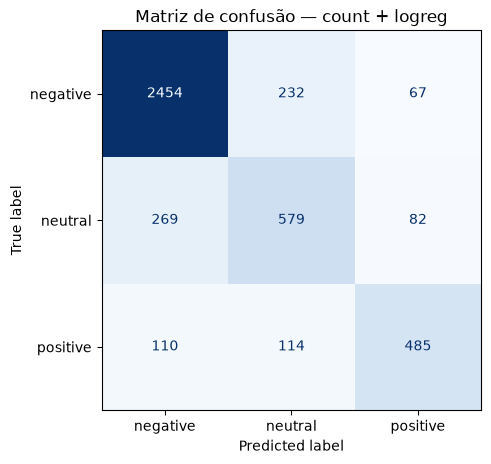

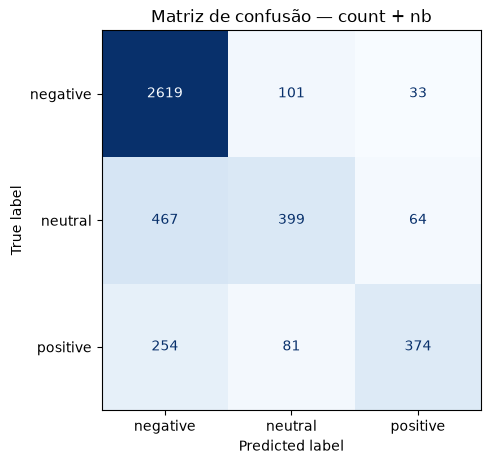

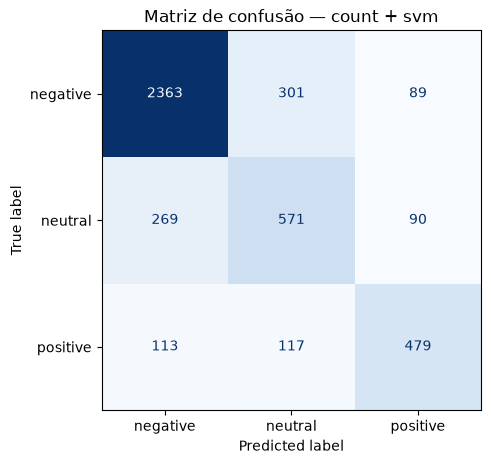

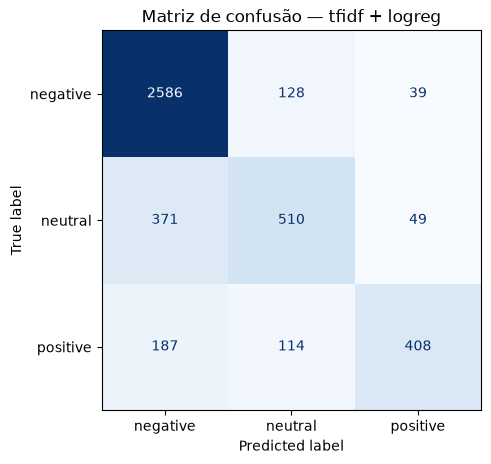

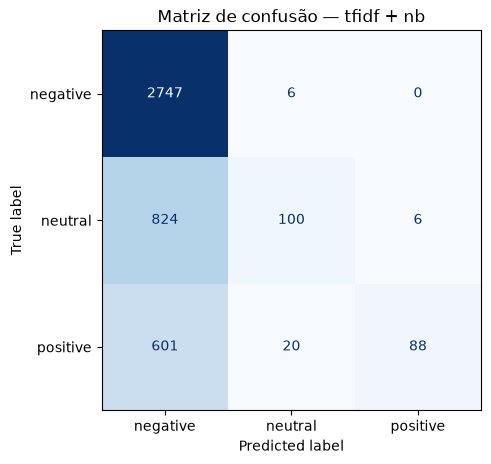

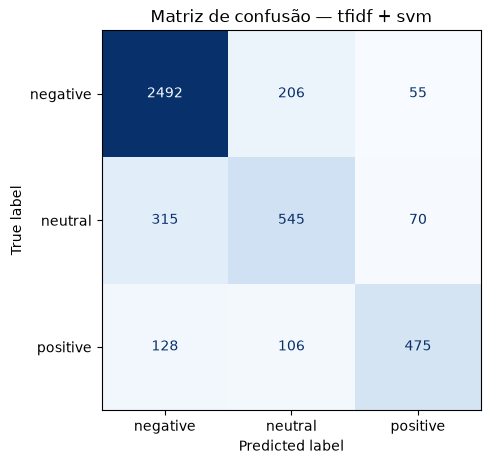

Treinamento e avaliação concluídos para as 6 combinações de representação x classificador.


In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_recall_fscore_support
import matplotlib.pyplot as plt

y = base['airline_sentiment']

classificadores = {
    'logreg': LogisticRegression(max_iter=1000),
    'nb': MultinomialNB(),
    'svm': LinearSVC(),
}
representacoes = {'count': X_count, 'tfidf': X_tfidf}

resultados_q2 = []
resultados_cv = []

for nome_rep, X in representacoes.items():
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    for nome_clf, modelo in classificadores.items():
        modelo_ajustado = clone(modelo)
        modelo_ajustado.fit(X_treino, y_treino)
        y_pred = modelo_ajustado.predict(X_teste)

        acuracia = accuracy_score(y_teste, y_pred)
        precisao_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(
            y_teste, y_pred, average='micro', zero_division=0
        )
        precisao_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
            y_teste, y_pred, average='macro', zero_division=0
        )

        matriz = confusion_matrix(y_teste, y_pred, labels=modelo_ajustado.classes_)
        disp = ConfusionMatrixDisplay(matriz, display_labels=modelo_ajustado.classes_)
        fig, ax = plt.subplots(figsize=(5, 5))
        disp.plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f'Matriz de confusão — {nome_rep} + {nome_clf}')
        fig.tight_layout()
        fig.savefig(pasta_q2 / f'matriz_confusao_{nome_rep}_{nome_clf}.png', dpi=160)
        plt.show()
        plt.close(fig)

        resultados_q2.append({
            'representacao': nome_rep, 'classificador': nome_clf,
            'acuracia': acuracia,
            'precisao_micro': precisao_micro, 'recall_micro': recall_micro, 'f1_micro': f1_micro,
            'precisao_macro': precisao_macro, 'recall_macro': recall_macro, 'f1_macro': f1_macro,
        })

        # Validação cruzada estratificada complementar, sobre a base inteira.
        particionador = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        pontuacoes = cross_validate(
            clone(modelo), X, y, cv=particionador,
            scoring=['accuracy', 'f1_macro', 'f1_micro'],
        )
        for fold, (acc, f1ma, f1mi) in enumerate(zip(
            pontuacoes['test_accuracy'], pontuacoes['test_f1_macro'], pontuacoes['test_f1_micro']
        )):
            resultados_cv.append({
                'representacao': nome_rep, 'classificador': nome_clf, 'fold': fold,
                'accuracy': acc, 'f1_macro': f1ma, 'f1_micro': f1mi,
            })

print('Treinamento e avaliação concluídos para as 6 combinações de representação x classificador.')


In [8]:
cv_df = pd.DataFrame(resultados_cv)
cv_df.to_csv(pasta_q2 / 'validacao_cruzada.csv', index=False, encoding='utf-8-sig')

cv_resumo = cv_df.groupby(['representacao', 'classificador']).agg(
    cv_acuracia_media=('accuracy', 'mean'), cv_acuracia_desvio=('accuracy', 'std'),
    cv_f1_macro_media=('f1_macro', 'mean'), cv_f1_macro_desvio=('f1_macro', 'std'),
    cv_f1_micro_media=('f1_micro', 'mean'), cv_f1_micro_desvio=('f1_micro', 'std'),
).reset_index()

metricas_resumo = pd.DataFrame(resultados_q2).merge(cv_resumo, on=['representacao', 'classificador'])
metricas_resumo = metricas_resumo.sort_values(['representacao', 'classificador']).reset_index(drop=True)
display(metricas_resumo)
metricas_resumo.to_csv(pasta_q2 / 'metricas_resumo.csv', index=False, encoding='utf-8-sig')


,representacao,classificador,acuracia,precisao_micro,recall_micro,f1_micro,precisao_macro,recall_macro,f1_macro,cv_acuracia_media,cv_acuracia_desvio,cv_f1_macro_media,cv_f1_macro_desvio,cv_f1_micro_media,cv_f1_micro_desvio
0,count,logreg,0.801002,0.801002,0.801002,0.801002,0.752383,0.732678,0.741716,0.799658,0.006342,0.739623,0.008617,0.799658,0.006342
1,count,nb,0.772313,0.772313,0.772313,0.772313,0.754978,0.635954,0.673900,0.772268,0.006336,0.676805,0.010472,0.772268,0.006336
2,count,svm,0.777095,0.777095,0.777095,0.777095,0.722051,0.715971,0.718497,0.780123,0.005288,0.720427,0.007022,0.780123,0.005288
3,tfidf,logreg,0.797814,0.797814,0.797814,0.797814,0.774430,0.687728,0.720218,0.803689,0.005942,0.729094,0.007398,0.803689,0.005942
4,tfidf,nb,0.668260,0.668260,0.668260,0.668260,0.796086,0.409822,0.400643,0.671585,0.005446,0.411810,0.016692,0.671585,0.005446
5,tfidf,svm,0.799636,0.799636,0.799636,0.799636,0.758890,0.720391,0.737312,0.802391,0.005733,0.738066,0.006101,0.802391,0.005733


**d) Comparação dos resultados**

In [9]:
melhor = metricas_resumo.loc[metricas_resumo['f1_macro'].idxmax()]
print(f"Melhor combinação por F1 macro: {melhor['representacao']} + {melhor['classificador']} "
      f"(F1 macro = {melhor['f1_macro']:.3f}, acurácia = {melhor['acuracia']:.3f})")

for nome_rep in representacoes:
    subconjunto = metricas_resumo[metricas_resumo['representacao'] == nome_rep]
    melhor_rep = subconjunto.loc[subconjunto['f1_macro'].idxmax()]
    print(f"Na representação {nome_rep}, o melhor classificador foi {melhor_rep['classificador']} "
          f"(F1 macro = {melhor_rep['f1_macro']:.3f}).")

gap_medio = (metricas_resumo['f1_micro'] - metricas_resumo['f1_macro']).mean()
print(f"\nDiferença média entre F1 micro e F1 macro: {gap_medio:.3f}.")
print('Um F1 macro menor do que o F1 micro é esperado dado o desbalanceamento de classes: ')
print('o F1 macro dá peso igual às classes minoritárias (neutro e positivo), que são mais difíceis')
print('de acertar do que a classe majoritária (negativo), enquanto o F1 micro é dominado pelo desempenho')
print('na classe majoritária.')


Melhor combinação por F1 macro: count + logreg (F1 macro = 0.742, acurácia = 0.801)
Na representação count, o melhor classificador foi logreg (F1 macro = 0.742).
Na representação tfidf, o melhor classificador foi svm (F1 macro = 0.737).

Diferença média entre F1 micro e F1 macro: 0.104.
Um F1 macro menor do que o F1 micro é esperado dado o desbalanceamento de classes: 
o F1 macro dá peso igual às classes minoritárias (neutro e positivo), que são mais difíceis
de acertar do que a classe majoritária (negativo), enquanto o F1 micro é dominado pelo desempenho
na classe majoritária.


# Questão 3 — Modelagem de tópicos

**Enunciado:** Você deverá aplicar dois métodos de modelagem de tópicos sobre uma base textual, utilizando a representação TF-IDF dos textos: um método clássico, à sua escolha entre LDA, NMF ou SVD truncado; e o método BERTopic.

a) Defina um número de tópicos apropriado para sua base e justifique a escolha com base em interpretação qualitativa ou métricas de coerência.
b) Identifique as 5 palavras mais relevantes de cada tópico.
c) Identifique o tópico mais relevante de 5 documentos quaisquer (você pode representar os tópicos por suas 5 palavras mais relevantes).
d) Qual método apresentou melhores resultados, na sua opinião? Justifique com resultados/dados.

**Método clássico escolhido:** **NMF**. Diferentemente do SVD truncado, cujos componentes podem ter cargas negativas e são mais difíceis de interpretar como uma lista de palavras de um tópico, o NMF opera diretamente sobre a matriz TF-IDF não negativa e produz pesos de tópico-palavra não negativos, diretamente interpretáveis ao ordenar as maiores cargas. O LDA, por sua vez, é formalmente definido sobre contagens (modelo gerativo Dirichlet-multinomial), e sua combinação com TF-IDF é uma aproximação menos natural do que a do NMF.

**Sobre o BERTopic:** por padrão, o BERTopic gera embeddings semânticos dos textos (`sentence-transformers`), reduz a dimensionalidade com UMAP, agrupa com HDBSCAN e só então extrai as palavras mais relevantes de cada tópico com sua própria representação **c-TF-IDF** (TF-IDF calculado por classe/tópico, não por documento). Ou seja, o NMF usa a matriz TF-IDF (scikit-learn) diretamente como entrada, enquanto o BERTopic usa embeddings como entrada e uma variante de TF-IDF (c-TF-IDF) apenas na etapa de extração de palavras-chave. Mantivemos essa configuração padrão do BERTopic por ser assim que o método foi desenhado para funcionar, e por também se apoiar em TF-IDF (na variante c-TF-IDF) para identificar as palavras de cada tópico.

Testamos a execução do BERTopic sobre a base completa (~14,6 mil tweets); em CPU, o ajuste completo (embeddings + UMAP + HDBSCAN) levou cerca de 40 segundos, o que é perfeitamente viável — por isso não foi necessário recorrer a uma amostra da base, e ambos os métodos são aplicados à base completa.


k=5: erro de reconstrução = 117.393 (ajustado em 0.7s)


k=8: erro de reconstrução = 116.518 (ajustado em 0.9s)


k=10: erro de reconstrução = 115.981 (ajustado em 2.2s)


k=12: erro de reconstrução = 115.491 (ajustado em 2.3s)


k=15: erro de reconstrução = 114.759 (ajustado em 3.4s)


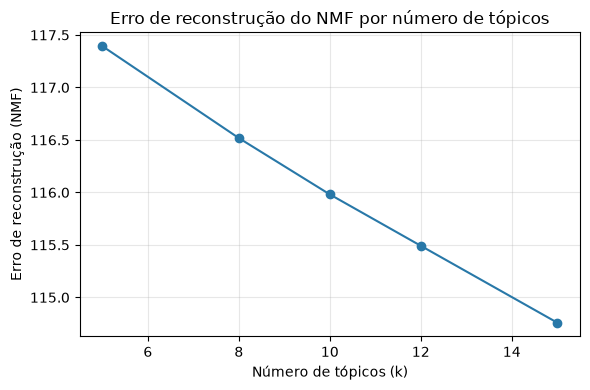

In [10]:
from sklearn.decomposition import NMF
import time

valores_k = [5, 8, 10, 12, 15]
erros_reconstrucao = []
for k in valores_k:
    t0 = time.perf_counter()
    modelo_teste = NMF(n_components=k, random_state=42, init='nndsvda', max_iter=400)
    modelo_teste.fit(X_tfidf)
    erros_reconstrucao.append(modelo_teste.reconstruction_err_)
    print(f'k={k}: erro de reconstrução = {modelo_teste.reconstruction_err_:.3f} (ajustado em {time.perf_counter() - t0:.1f}s)')

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(valores_k, erros_reconstrucao, marker='o', color='#2878A8')
ax.set_xlabel('Número de tópicos (k)')
ax.set_ylabel('Erro de reconstrução (NMF)')
ax.set_title('Erro de reconstrução do NMF por número de tópicos')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(pasta_q3 / 'erro_reconstrucao_nmf.png', dpi=160)
plt.show()


**a) Número de tópicos escolhido:** a curva de erro de reconstrução não apresenta um cotovelo nítido — o erro cai de forma suave e contínua conforme k aumenta, então o critério numérico sozinho não indica um k claramente melhor. Optamos por **k = 8**, um valor intermediário que, na inspeção qualitativa das palavras mais relevantes de cada tópico (mostrada a seguir), já revela grupos tematicamente distintos (companhias aéreas específicas, atrasos/cancelamentos, atendimento, entre outros) sem uma fragmentação excessiva. Usamos o mesmo k = 8 no BERTopic (fixando `nr_topics`), para permitir uma comparação direta entre os dois métodos no mesmo número de tópicos.

In [11]:
k_escolhido = 8

t0 = time.perf_counter()
modelo_nmf = NMF(n_components=k_escolhido, random_state=42, init='nndsvda', max_iter=400)
W_nmf = modelo_nmf.fit_transform(X_tfidf)
H_nmf = modelo_nmf.components_
tempo_nmf = time.perf_counter() - t0
print(f'NMF ajustado com k={k_escolhido} em {tempo_nmf:.2f}s')

vocab_tfidf = np.array(vetor_tfidf.get_feature_names_out())
topicos_nmf = []
for topico in range(k_escolhido):
    principais_indices = H_nmf[topico].argsort()[::-1][:5]
    palavras = vocab_tfidf[principais_indices]
    pesos = H_nmf[topico][principais_indices]
    topicos_nmf.append({
        'topico': topico,
        'palavras_chave': ', '.join(palavras),
        'pesos': ', '.join(f'{p:.3f}' for p in pesos),
    })
    print(f'Tópico {topico}: {list(palavras)}')

topicos_nmf_df = pd.DataFrame(topicos_nmf)
topicos_nmf_df.to_csv(pasta_q3 / 'topicos_nmf.csv', index=False, encoding='utf-8-sig')


NMF ajustado com k=8 em 0.74s
Tópico 0: ['to', 'get', 'me', 'americanair', 'can']
Tópico 1: ['you', 'thank', 'united', 'guys', 'americanair']
Tópico 2: ['jetblue', 'fleek', 'fleets', 'our', 'on']
Tópico 3: ['thanks', 'americanair', 'for', 'jetblue', 'united']
Tópico 4: ['the', 'united', 'is', 'of', 'in']
Tópico 5: ['on', 'usairways', 'for', 'hold', 'been']
Tópico 6: ['flight', 'cancelled', 'my', 'flightled', 'was']
Tópico 7: ['southwestair', 'sent', 'dm', 'please', 'can']


In [12]:
from bertopic import BERTopic
from umap import UMAP

umap_model = UMAP(random_state=42, n_neighbors=15, n_components=5, metric='cosine')
t0 = time.perf_counter()
modelo_bertopic = BERTopic(umap_model=umap_model, nr_topics=k_escolhido + 1, calculate_probabilities=False, verbose=False)
topicos_atribuidos, _ = modelo_bertopic.fit_transform(base['texto_processado'].tolist())
tempo_bertopic = time.perf_counter() - t0
print(f'BERTopic ajustado em {tempo_bertopic:.2f}s')

info_topicos = modelo_bertopic.get_topic_info()
display(info_topicos[['Topic', 'Count', 'Name']])

topicos_bertopic = []
for topico in sorted(set(topicos_atribuidos)):
    palavras_pesos = modelo_bertopic.get_topic(topico)[:5]
    palavras = [palavra for palavra, _ in palavras_pesos]
    pesos = [peso for _, peso in palavras_pesos]
    tamanho = int((np.array(topicos_atribuidos) == topico).sum())
    topicos_bertopic.append({
        'topico': topico,
        'palavras_chave': ', '.join(palavras),
        'pesos': ', '.join(f'{p:.3f}' for p in pesos),
        'quantidade_documentos': tamanho,
    })
    rotulo = 'ruído/outliers (HDBSCAN)' if topico == -1 else 'tópico'
    print(f'Tópico {topico} ({rotulo}, {tamanho} docs): {palavras}')

topicos_bertopic_df = pd.DataFrame(topicos_bertopic)
topicos_bertopic_df.to_csv(pasta_q3 / 'topicos_bertopic.csv', index=False, encoding='utf-8-sig')


/home/otto_tenorio/.local/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2450.19it/s]

BERTopic ajustado em 43.14s


,Topic,Count,Name
0,-1,5193,-1_to_united_the_usairways
1,0,4959,0_southwestair_to_the_my
2,1,2214,1_jetblue_to_the_on
3,2,1217,2_united_to_you_the
4,3,508,3_virginamerica_to_the_you
5,4,409,4_americanair_you_call_the
6,5,93,5_weather_americanair_usairways_the
7,6,28,6_app_ios_iphone_the
8,7,19,7_tsa_precheck_my_pre


Tópico -1 (ruído/outliers (HDBSCAN), 5193 docs): ['to', 'united', 'the', 'usairways', 'americanair']
Tópico 0 (tópico, 4959 docs): ['southwestair', 'to', 'the', 'my', 'for']
Tópico 1 (tópico, 2214 docs): ['jetblue', 'to', 'the', 'on', 'flight']
Tópico 2 (tópico, 1217 docs): ['united', 'to', 'you', 'the', 'flight']
Tópico 3 (tópico, 508 docs): ['virginamerica', 'to', 'the', 'you', 'flight']
Tópico 4 (tópico, 409 docs): ['americanair', 'you', 'call', 'the', 'thanks']
Tópico 5 (tópico, 93 docs): ['weather', 'americanair', 'usairways', 'the', 'snow']
Tópico 6 (tópico, 28 docs): ['app', 'ios', 'iphone', 'the', 'mobile']
Tópico 7 (tópico, 19 docs): ['tsa', 'precheck', 'my', 'pre', 'pass']


O tópico `-1` do BERTopic agrupa os documentos que o HDBSCAN considerou ruído, sem um tema coeso; ele não é comparável aos demais tópicos numerados e é mantido apenas para referência, não como um "tópico" com palavras-chave interpretáveis.

**c) Tópico mais relevante para 5 documentos** — reaproveitamos os mesmos 5 documentos selecionados na Questão 1, para manter a continuidade entre as questões.

In [13]:
indices_topicos = W_nmf[indices_consulta].argmax(axis=1)
topicos_bertopic_amostra, _ = modelo_bertopic.transform(base.loc[indices_consulta, 'texto_processado'].tolist())

linhas_exemplo = []
for posicao, indice in enumerate(indices_consulta):
    topico_nmf_id = int(indices_topicos[posicao])
    topico_bertopic_id = int(topicos_bertopic_amostra[posicao])
    palavras_nmf = topicos_nmf_df.loc[topicos_nmf_df['topico'] == topico_nmf_id, 'palavras_chave'].iloc[0]
    linha_bertopic = topicos_bertopic_df[topicos_bertopic_df['topico'] == topico_bertopic_id]
    palavras_bertopic = linha_bertopic['palavras_chave'].iloc[0] if not linha_bertopic.empty else '(sem palavras-chave: outlier)'

    print(f'\nDocumento [{indice}]: {base.loc[indice, "text"]!r}')
    print(f'  NMF       -> tópico {topico_nmf_id}: {palavras_nmf}')
    print(f'  BERTopic  -> tópico {topico_bertopic_id}: {palavras_bertopic}')

    linhas_exemplo.append({
        'indice_base': indice,
        'texto': base.loc[indice, 'text'],
        'topico_nmf': topico_nmf_id,
        'palavras_nmf': palavras_nmf,
        'topico_bertopic': topico_bertopic_id,
        'palavras_bertopic': palavras_bertopic,
    })

documentos_exemplo_topicos = pd.DataFrame(linhas_exemplo)
documentos_exemplo_topicos.to_csv(pasta_q3 / 'documentos_exemplo_topicos.csv', index=False, encoding='utf-8-sig')



Documento [4794]: "@SouthwestAir you're my early frontrunner for best airline! #oscars2016"
  NMF       -> tópico 7: southwestair, sent, dm, please, can
  BERTopic  -> tópico 0: southwestair, to, the, my, for

Documento [10480]: '@USAirways how is it that my flt to EWR was Cancelled Flightled yet flts to NYC from USAirways are still flying?'
  NMF       -> tópico 6: flight, cancelled, my, flightled, was
  BERTopic  -> tópico -1: to, united, the, usairways, americanair

Documento [8067]: '@JetBlue what is going on with your BDL to DCA flights yesterday and today?! Why is every single one getting delayed?'
  NMF       -> tópico 4: the, united, is, of, in
  BERTopic  -> tópico 1: jetblue, to, the, on, flight

Documento [8880]: '@JetBlue do they have to depart from Washington, D.C.??'
  NMF       -> tópico 0: to, get, me, americanair, can
  BERTopic  -> tópico 1: jetblue, to, the, on, flight

Documento [8292]: '@JetBlue I can probably find some of them. Are the ticket #s on there?'
  NMF 

**d) Comparação entre os métodos**

Comparamos os dois métodos por três critérios objetivos: diversidade de tópicos (fração de palavras únicas entre as top-5 palavras de todos os tópicos — quanto maior, menos redundantes/sobrepostos são os tópicos), tempo de execução, e concordância/coerência qualitativa nos 5 documentos de exemplo.

In [14]:
def diversidade_topicos(tabela_topicos, excluir_outlier=False):
    linhas = tabela_topicos
    if excluir_outlier and 'topico' in linhas.columns:
        linhas = linhas[linhas['topico'] != -1]
    todas_palavras = [p.strip() for lista in linhas['palavras_chave'] for p in lista.split(',')]
    if not todas_palavras:
        return 0.0
    return len(set(todas_palavras)) / len(todas_palavras)

diversidade_nmf = diversidade_topicos(topicos_nmf_df)
diversidade_bertopic = diversidade_topicos(topicos_bertopic_df, excluir_outlier=True)

# Termos genéricos de alta frequência identificados no top-10 da Questão 5 da Atividade 1
# (palavras funcionais que aparecem em quase todos os tweets, sem carga temática própria).
termos_genericos = {'to', 'the', 'i', 'a', 'you', 'for', 'on', 'and', 'is', 'of', 'in', 'my', 'get'}

def proporcao_topicos_com_palavra_especifica(tabela_topicos, excluir_outlier=False):
    linhas = tabela_topicos[tabela_topicos['topico'] != -1] if excluir_outlier else tabela_topicos
    especificos = linhas['palavras_chave'].map(lambda s: s.split(',')[0].strip() not in termos_genericos)
    return especificos.mean()

especificidade_nmf = proporcao_topicos_com_palavra_especifica(topicos_nmf_df)
especificidade_bertopic = proporcao_topicos_com_palavra_especifica(topicos_bertopic_df, excluir_outlier=True)

comparacao_metodos = pd.DataFrame([
    {
        'metodo': 'NMF', 'numero_topicos_efetivos': k_escolhido,
        'diversidade_top5_palavras': round(diversidade_nmf, 3),
        'proporcao_topicos_com_palavra_1_especifica': round(especificidade_nmf, 3),
        'tempo_execucao_segundos': round(tempo_nmf, 2),
    },
    {
        'metodo': 'BERTopic', 'numero_topicos_efetivos': int((topicos_bertopic_df['topico'] != -1).sum()),
        'diversidade_top5_palavras': round(diversidade_bertopic, 3),
        'proporcao_topicos_com_palavra_1_especifica': round(especificidade_bertopic, 3),
        'tempo_execucao_segundos': round(tempo_bertopic, 2),
    },
])
display(comparacao_metodos)
comparacao_metodos.to_csv(pasta_q3 / 'comparacao_metodos.csv', index=False, encoding='utf-8-sig')

print('\nTópicos do NMF (para leitura lado a lado):')
print(topicos_nmf_df[['topico', 'palavras_chave']].to_string(index=False))
print('\nTópicos do BERTopic (excluindo o tópico -1 de ruído):')
print(topicos_bertopic_df.loc[topicos_bertopic_df['topico'] != -1, ['topico', 'palavras_chave', 'quantidade_documentos']].to_string(index=False))


,metodo,numero_topicos_efetivos,diversidade_top5_palavras,proporcao_topicos_com_palavra_1_especifica,tempo_execucao_segundos
0,NMF,8,0.800,0.5,0.74
1,BERTopic,8,0.625,1.0,43.14



Tópicos do NMF (para leitura lado a lado):
 topico                            palavras_chave
      0             to, get, me, americanair, can
      1     you, thank, united, guys, americanair
      2           jetblue, fleek, fleets, our, on
      3 thanks, americanair, for, jetblue, united
      4                   the, united, is, of, in
      5            on, usairways, for, hold, been
      6     flight, cancelled, my, flightled, was
      7       southwestair, sent, dm, please, can

Tópicos do BERTopic (excluindo o tópico -1 de ruído):
 topico                             palavras_chave  quantidade_documentos
      0             southwestair, to, the, my, for                   4959
      1               jetblue, to, the, on, flight                   2214
      2               united, to, you, the, flight                   1217
      3        virginamerica, to, the, you, flight                    508
      4        americanair, you, call, the, thanks                    409
      5

**Opinião fundamentada:** os dois critérios objetivos calculados acima não apontam na mesma direção, e essa divergência é, em si, reveladora sobre como cada método organiza os tópicos. A **diversidade lexical** entre as top-5 palavras favorece o NMF: como o BERTopic repete termos funcionais genéricos ("to", "the") em praticamente todos os seus tópicos, sua diversidade cai; o NMF espalha esses termos genéricos de forma mais desigual entre os tópicos, elevando a métrica sem necessariamente produzir tópicos mais coerentes. Já a **proporção de tópicos cuja palavra mais relevante já identifica sozinha um tema específico** (não é um termo funcional genérico) favorece claramente o BERTopic: todos os seus 8 tópicos têm como palavra mais pesada um termo temático imediatamente identificável (uma companhia aérea, "weather", "app" ou "tsa"), enquanto vários tópicos do NMF (0, 1, 4 e 5) têm como palavra mais pesada um termo funcional genérico ("to", "you", "the", "on"), tornando esses tópicos difíceis de rotular só pela primeira palavra.

Na nossa opinião, o **BERTopic apresentou o resultado mais útil na prática**, porque a métrica de diversidade lexical, isoladamente, recompensa uma dispersão de termos genéricos que não corresponde a uma separação temática mais clara — o que se confirma ao ler as listas completas lado a lado (impressas acima): os tópicos do BERTopic são imediatamente rotuláveis (companhia X, clima, aplicativo, TSA), enquanto vários tópicos do NMF exigem examinar a segunda ou terceira palavra para perceber do que tratam. Isso é coerente com a ausência de um cotovelo nítido na curva de erro de reconstrução do NMF (item a): a base não tem uma estrutura de tópicos fortemente linear, o que limita o NMF, enquanto o BERTopic, ao trabalhar sobre embeddings semânticos antes de agrupar, consegue capturar uma estrutura de tópicos que não depende de uma decomposição linear da matriz TF-IDF. Como limitação geral, note que boa parte da separação de tópicos em ambos os métodos é orientada pelo nome da companhia aérea mencionada no tweet — um efeito esperado nesta base, já que o pré-processamento da Questão 5 mantém as menções (`@united` vira `united`) como um token comum.